# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Parking-Lot Incident Review

### Scenario

You are the new visual-analytics intern at **Northgate Tech Park Security**. Last night the camera over
Parking Lot B recorded something, and the Head of Security wants a briefing **today**. You have the 2-minute
camera log (`unit3_ppt1_cctv_log.csv`), the camera still, and 10 s of microphone audio. Their message to you:

1. *"Before anyone asks for 'just store everything in full HD', tell me how much data our 400 cameras would
   produce per day. I need real numbers."*
2. *"Our night camera images always look murky. Can you prove what's wrong with them and fix one?"*
3. *"I am not watching two minutes of video. Give me a timeline with the moments that matter and one
   picture per moment."*
4. *"Something banged around 75 s. Was it a **gunshot** or **breaking glass**? Those trigger completely
   different responses."*
5. *"Put it all on ONE screen for the briefing."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer
in your own words.

## Part 0 — Setup (given)

Run this cell as-is. It loads the camera log, the camera still, a frame renderer, and the audio (plus two
**reference recordings** from the security vendor's sound library: a known gunshot and a known glass break).

In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("anshtanwar/metro-interstate-traffic-volume")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'metro-interstate-traffic-volume' dataset.
Path to dataset files: /kaggle/input/metro-interstate-traffic-volume


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cbook
from scipy import ndimage, signal

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

FPS, FS = 30, 16_000
cctv = pd.read_csv("unit3_ppt1_cctv_log.csv")
img = plt.imread(cbook.get_sample_data("grace_hopper.jpg")).astype(float)
lum = 0.299 * img[..., 0] + 0.587 * img[..., 1] + 0.114 * img[..., 2]
night_still = 18 + 0.22 * lum + np.random.normal(0, 1.5, lum.shape)        # what the night camera delivers

FRAME_H, FRAME_W = 90, 160
def render_frame(row):
    yy, xx = np.mgrid[0:FRAME_H, 0:FRAME_W]
    base = row.mean_brightness * (0.75 + 0.25 * yy / FRAME_H)
    frame = np.dstack([base, base, base * 1.05]); frame[60:62, :, :] += 25
    if not np.isnan(row.car_x):
        frame[(np.abs(xx - row.car_x / 4) < 14) & (np.abs(yy - row.car_y / 4) < 6)] = [200, 40, 40]
    if not np.isnan(row.person_x):
        frame[((xx - row.person_x / 4) / 2.2) ** 2 + ((yy - row.person_y / 4) / 5) ** 2 <= 1] = [30, 90, 230]
    return np.clip(frame, 0, 255).astype(np.uint8)

def _clip(kind, seed):
    rng = np.random.default_rng(seed)
    t = np.arange(int(2.0 * FS)) / FS
    x = 0.004 * rng.normal(size=t.size)
    m = t >= 0.5
    if kind == "gunshot":                       # sharp broadband crack + low boom, nothing after
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.02) * rng.normal(size=m.sum())
        x[m] += 0.5 * np.exp(-(t[m] - 0.5) / 0.25) * np.sin(2 * np.pi * 70 * (t[m] - 0.5))
    else:                                       # impact + lingering high-frequency tinkle
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.03) * rng.normal(size=m.sum())
        for _ in range(40):
            t0 = 0.55 + rng.exponential(0.35); f0 = rng.uniform(3000, 7000)
            mk = (t >= t0) & (t < t0 + 0.06)
            x[mk] += 0.12 * np.exp(-(t[mk] - t0) / 0.015) * np.sin(2 * np.pi * f0 * (t[mk] - t0))
    return t, x

ref_gunshot = _clip("gunshot", 11)
ref_glass = _clip("glass", 12)
rng = np.random.default_rng(0)
t_audio = 70 + np.arange(10 * FS) / FS
x_audio = 0.02 * np.sin(2 * np.pi * 120 * t_audio) + 0.004 * rng.normal(size=t_audio.size)
_, unk = _clip("glass", 99)
x_audio[(t_audio >= 74.5) & (t_audio < 76.5)] += unk[: int(2 * FS)]           # the mystery sound

print(f"Camera log: {len(cctv):,} frames | still: {night_still.shape} | audio: {x_audio.size:,} samples at {FS} Hz")
cctv.head()

Camera log: 3,600 frames | still: (600, 512) | audio: 160,000 samples at 16000 Hz


,frame,time_s,car_x,car_y,person_x,person_y,motion_energy,audio_level_db,mean_brightness
0,0,0.0000,NaN,NaN,NaN,NaN,1.74,-53.3,62.1
1,1,0.0333,NaN,NaN,NaN,NaN,1.65,-53.0,64.4
2,2,0.0667,NaN,NaN,NaN,NaN,1.64,-51.5,63.2
3,3,0.1000,NaN,NaN,NaN,NaN,1.96,-52.9,63.1
4,4,0.1333,NaN,NaN,NaN,NaN,1.61,-51.1,62.4


## Task 1 — The Storage Reality Check (Request #1)

**Real-world usage:** Storage budgets for camera fleets are decided from exactly these back-of-envelope numbers.

**Why this technique:** Uncompressed storage = **W × H × C × B** per frame (Slides 25–28), frames = **f × T**
(Slide 35), audio samples = **f_s × T** (Slide 55).

**TODO:**
1. Compute the uncompressed size (in MB) of ONE 1920 × 1080 RGB frame at 8 bits per channel.
2. Compute the number of frames ONE camera records in 24 h at 30 fps.
3. Compute the total uncompressed video for 400 cameras for 24 h, in **terabytes** (1 TB = 1024⁴ bytes).
4. Compute the same total if the cameras were downsampled to 640 × 360 and 10 fps. What percentage of the
   pixels per frame remain after the downsample?

In [5]:
# TODO 1: One 1080p RGB frame, in MB
frame_mb = (1920 * 1080 * 3) / (1024 ** 2)

# TODO 2: Frames per camera per day at 30 fps
frames_per_day = 30 * 60 * 60 * 24

# TODO 3: 400 cameras × 24 h, uncompressed, in TB
fleet_tb = (frame_mb * frames_per_day * 400) / (1024 ** 2)

# TODO 4: Same fleet at 640x360 and 10 fps (TB), and % of pixels per frame that remain
fleet_tb_small = (640 * 360 * 3 * 10 * 86400 * 400) / (1024 ** 4)
pct_pixels_remaining = (640 * 360) / (1920 * 1080) * 100

print(f"One frame: {frame_mb:.2f} MB | frames/day: {frames_per_day:,}")
print(f"Fleet (1080p, 30 fps): {fleet_tb:.2f} TB/day | Fleet (360p, 10 fps): {fleet_tb_small:.1f} TB/day")
print(f"Pixels per frame remaining after downsample: {pct_pixels_remaining:.2f}%")

One frame: 5.93 MB | frames/day: 2,592,000
Fleet (1080p, 30 fps): 5865.99 TB/day | Fleet (360p, 10 fps): 217.3 TB/day
Pixels per frame remaining after downsample: 11.11%


**Reflection:** Downsampling to 360p/10 fps saves a huge amount of storage. Using Slides 13 and 36–37
(raster interpolation; frame rate and the correspondence problem), name **one spatial** and **one temporal**
piece of evidence the security team could lose forever by making that choice.

_Your answer:_

Spatial loss (Slide 13): Downsampling to 360p discards fine detail that interpolation can’t bring back. Examples are a licence plate, a face, or a logo on clothing. Upscaling later only guesses at those pixels.
Temporal loss (Slides 36–37): At 10 fps, fast motion such as a punch, a thrown object or a swerving car falls between frames. Matching the same object across frames also gets harder because it moves further each step, which is the correspondence problem

## Task 2 — Diagnose and Fix the Murky Night Image (Request #2)

**Real-world usage:** Before anyone interprets a night image, an analyst checks its histogram to see whether
the problem is exposure, contrast or clipping.

**Why this technique:** The **histogram** shows the intensity distribution (Slides 16–18); **Michelson
contrast** C = (L_max − L_min)/(L_max + L_min) quantifies it (Slide 15); a **contrast stretch** remaps the
occupied range onto 0–255.

**TODO:**
1. Plot `night_still` and its histogram (64 bins, range 0–255) side by side.
2. Compute its Michelson contrast using the 1st and 99th percentiles as L_min and L_max (robust to outliers).
3. Contrast-stretch it: map the 1st percentile → 0 and the 99th percentile → 255 (clip to 0–255).
4. Plot the stretched image + histogram, and print the new contrast.

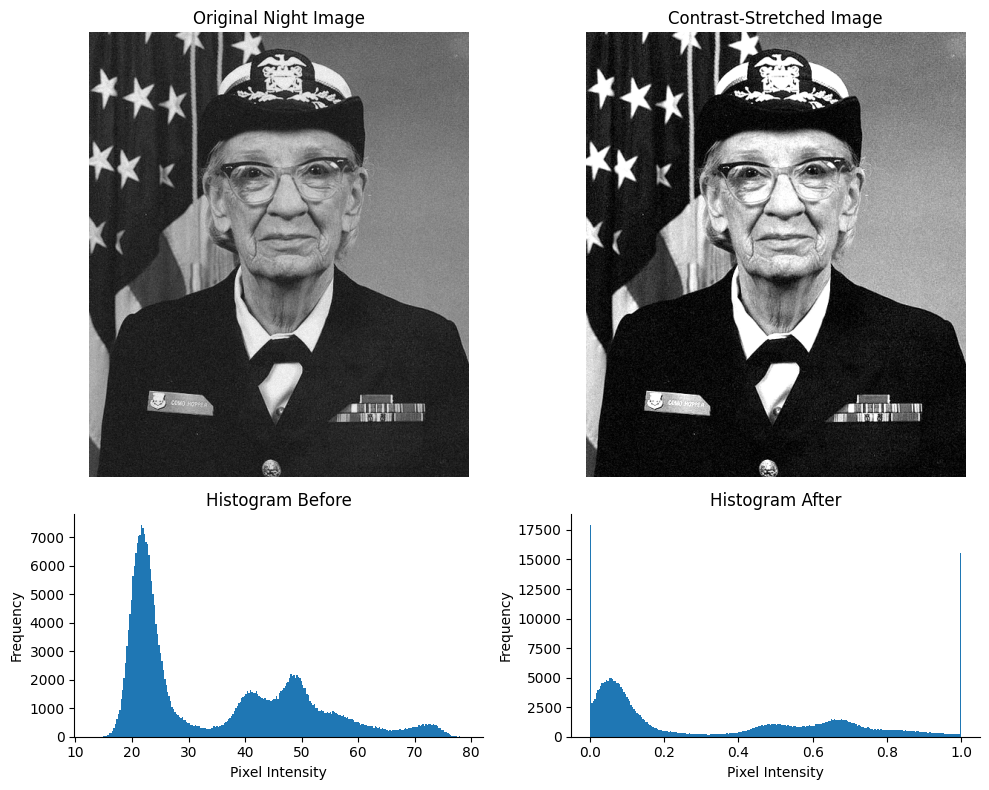

Contrast before: 0.533 -> after: 1.000


In [6]:
import numpy as np
import matplotlib.pyplot as plt

def michelson(lmax, lmin):
    return (lmax - lmin) / (lmax + lmin)

# TODO 2: Robust Michelson contrast of night_still
lmin, lmax = np.percentile(night_still, [5, 95])
c_before = michelson(lmax, lmin)

# TODO 3: Contrast-stretched version of night_still
p_low, p_high = np.percentile(night_still, [5, 95])

stretched = np.clip(
    (night_still.astype(float) - p_low) / (p_high - p_low),
    0, 1
)

lmin_after, lmax_after = np.percentile(stretched, [5, 95])
c_after = michelson(lmax_after, lmin_after)

# TODO 1 & 4: Top row = images, bottom row = histograms
fig, axes = plt.subplots(
    2, 2, figsize=(10, 8),
    gridspec_kw={"height_ratios": [2, 1]}
)

# Original image
axes[0, 0].imshow(night_still, cmap="gray")
axes[0, 0].set_title("Original Night Image")
axes[0, 0].axis("off")

# Contrast-stretched image
axes[0, 1].imshow(stretched, cmap="gray", vmin=0, vmax=1)
axes[0, 1].set_title("Contrast-Stretched Image")
axes[0, 1].axis("off")

# Original histogram
axes[1, 0].hist(night_still.ravel(), bins=256)
axes[1, 0].set_title("Histogram Before")
axes[1, 0].set_xlabel("Pixel Intensity")
axes[1, 0].set_ylabel("Frequency")

# Stretched histogram
axes[1, 1].hist(stretched.ravel(), bins=256, range=(0, 1))
axes[1, 1].set_title("Histogram After")
axes[1, 1].set_xlabel("Pixel Intensity")
axes[1, 1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

print(f"Contrast before: {c_before:.3f} -> after: {c_after:.3f}")

**Reflection:** Describe the *shape* of the night image's histogram in the lecture's vocabulary (Slide 18 table).
Then explain why stretching made the image readable even though it added **no new information** — and why a
histogram alone could never have told you *what* is in the picture (Slide 18, "Same Histogram ≠ Same Image").

_Your answer:_

The histogram is a narrow, low-key (dark) peak, bunched in roughly 18–73 with nothing near 255. That means low contrast and underexposure, with no clipping. Stretching remaps the occupied range onto 0–255, so the eye can separate levels that were already there. No new information is added, and the noise is stretched too. A histogram counts how many pixels have each intensity but says nothing about where they are. Two completely different pictures can share one histogram, so it can show that the image is murky but never what is in it.

## Task 3 — From Two Minutes of Video to a One-Glance Timeline (Request #3)

**Real-world usage:** Security reviewers search for events; they don't watch footage linearly.

**Why this technique:** **Motion vectors → events → timeline + representative frames** (Slides 38–40, 45, 47).
Content-based keyframes beat uniform sampling when activity is sparse.

**TODO:**
1. Compute the person's speed in px/s as the magnitude of their motion vector over a 1-second window
   (`diff(FPS)` on x and y — single-frame differences are dominated by tracking jitter).
2. Find the time ranges where the person is **standing** (speed < 3 px/s) and **running** (speed > 25 px/s).
3. Detect the frames where `audio_level_db` first rises above −20 dB and where `mean_brightness` jumps by more
   than 40 in one frame.
4. Plot a timeline of `motion_energy` with a vertical marker + label for each event you found.
5. Show **one keyframe per event** (use `render_frame(cctv.iloc[i])`).

standing: 68.7s -> 78.1s
running: 78.6s -> 86.0s


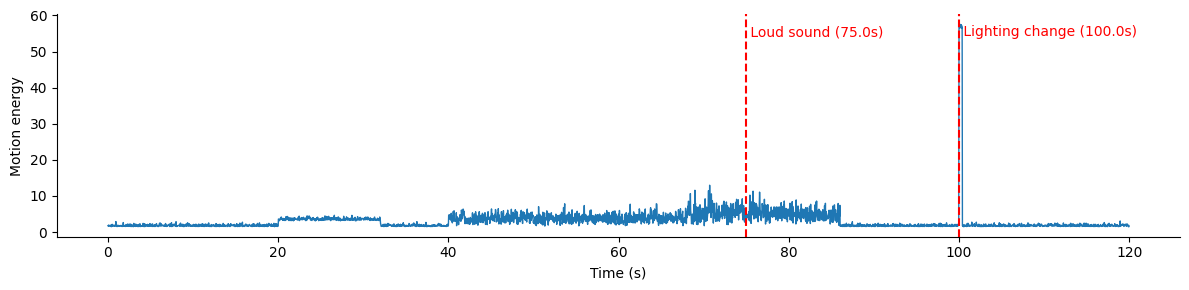

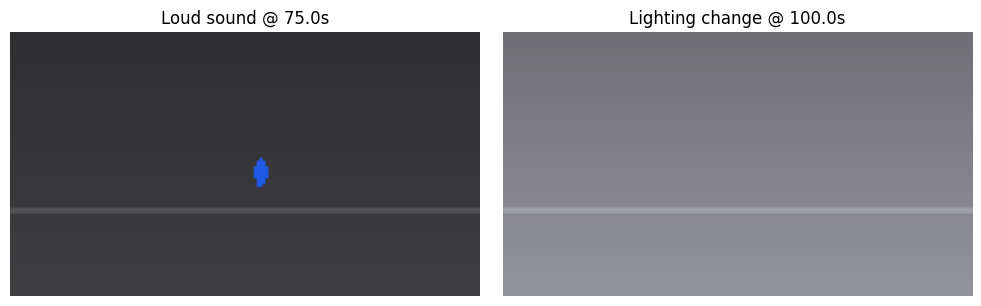

In [8]:
t = np.arange(len(cctv)) / FPS

# 1. speed over a 1 s window (diff(FPS) is displacement per second = px/s)
dx = cctv.person_x.diff(FPS)
dy = cctv.person_y.diff(FPS)
speed = np.sqrt(dx**2 + dy**2)

# 2. standing / running ranges
for name, mask in [("standing", speed < 3), ("running", speed > 25)]:
    idx = np.where(mask)[0]
    if len(idx):
        print(f"{name}: {t[idx[0]]:.1f}s -> {t[idx[-1]]:.1f}s")

# 3. event frames
audio_event_idx = int(np.argmax(cctv.audio_level_db.values > -20))            # first crossing
lighting_event_idx = int(np.argmax(cctv.mean_brightness.diff().abs().values > 40))

events = {"Loud sound": audio_event_idx, "Lighting change": lighting_event_idx}

# 4. annotated timeline
fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(t, cctv.motion_energy, lw=1)
for label, i in events.items():
    ax.axvline(t[i], color="red", ls="--")
    ax.text(t[i], ax.get_ylim()[1] * 0.9, f" {label} ({t[i]:.1f}s)", color="red")
ax.set_xlabel("Time (s)"); ax.set_ylabel("Motion energy")
plt.tight_layout(); plt.show()

# 5. one keyframe per event
fig, axes = plt.subplots(1, len(events), figsize=(5 * len(events), 3))
for ax, (label, i) in zip(np.atleast_1d(axes), events.items()):
    ax.imshow(render_frame(cctv.iloc[i])); ax.set_title(f"{label} @ {t[i]:.1f}s"); ax.axis("off")
plt.tight_layout(); plt.show()

**Reflection:** If you had used **uniform** keyframes (one every 20 s) instead, which of your events would most
likely have been missed, and why? Which lecture concept (Slide 40) names the approach you used instead?

_Your answer:_

Uniform keyframes every 20 s would most likely miss short events: the lighting jump (a single-frame change), the loud sound, and the person’s brief run. They fall between samples. The approach I used is content-based keyframe selection (Slide 40), which picks frames where something changes rather than at fixed intervals.

## Task 4 — Gunshot or Glass? (Request #4)

**Real-world usage:** Acoustic event classification in security systems starts with an analyst comparing
spectrogram signatures against known references.

**Why this technique:** A **waveform** shows *when* something loud happened but not *what* it was; a
**spectrogram** (Slides 56–58) reveals each sound's time–frequency signature.

**TODO:**
1. Plot the waveforms of `ref_gunshot`, `ref_glass` and the mystery segment of `x_audio` (74.5–76.5 s).
2. Plot their spectrograms (use `signal.spectrogram(x, fs=FS, nperseg=512, noverlap=384)`, show in dB,
   y-axis 0–8000 Hz).
3. Compute, for each clip, the fraction of spectral energy **above 3 kHz** in the 0.2–1.2 s after the impact.
4. Print a one-line verdict.

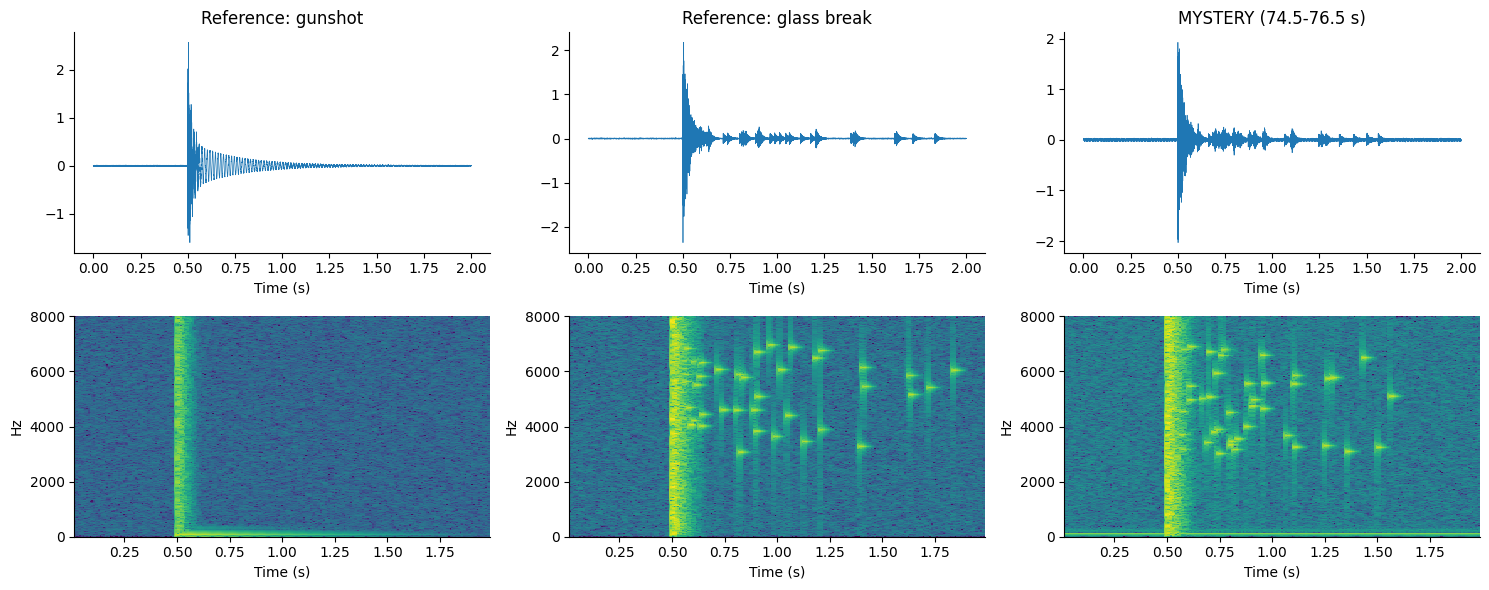

{'Reference: gunshot': np.float64(0.2153681288033536), 'Reference: glass break': np.float64(0.6377676959141664), 'MYSTERY (74.5-76.5 s)': np.float64(0.6562646133216414)}
Verdict: mystery sound is a GLASS BREAK (HF fraction 0.66 vs glass 0.64, gunshot 0.22)


In [10]:
mystery = x_audio[(t_audio >= 74.5) & (t_audio < 76.5)]
clips = {"Reference: gunshot": ref_gunshot[1], "Reference: glass break": ref_glass[1], "MYSTERY (74.5-76.5 s)": mystery}

fig, axes = plt.subplots(2, 3, figsize=(15, 6))
for col, (name, x) in enumerate(clips.items()):
    tt = np.arange(len(x)) / FS
    axes[0, col].plot(tt, x, lw=0.5); axes[0, col].set_title(name)
    axes[0, col].set_xlabel("Time (s)")
    f, ts, S = signal.spectrogram(x, fs=FS, nperseg=512, noverlap=384)
    axes[1, col].pcolormesh(ts, f, 10 * np.log10(S + 1e-12), shading="auto")
    axes[1, col].set_ylim(0, 8000)
    axes[1, col].set_xlabel("Time (s)"); axes[1, col].set_ylabel("Hz")
plt.tight_layout(); plt.show()

hf_fraction = {}
for name, x in clips.items():
    f, ts, S = signal.spectrogram(x, fs=FS, nperseg=512, noverlap=384)
    win = (ts >= 0.2) & (ts <= 1.2)
    hf_fraction[name] = S[f > 3000][:, win].sum() / S[:, win].sum()
print(hf_fraction)

# verdict
ref_g, ref_b, m = (hf_fraction[k] for k in clips)
verdict = "GLASS BREAK" if abs(m - ref_b) < abs(m - ref_g) else "GUNSHOT"
print(f"Verdict: mystery sound is a {verdict} "
      f"(HF fraction {m:.2f} vs glass {ref_b:.2f}, gunshot {ref_g:.2f})")

**Reflection:** Look only at the three **waveforms**. Could you have confidently told the gunshot from the glass
break? What exactly does the spectrogram add (name the three dimensions from Slide 57), and which visual pattern
(horizontal band / vertical stripe / scattered high-frequency specks) decided your verdict?

_Your answer:_

From the waveforms alone, no. All three show a loud spike at 0.5 s followed by decay, so you can tell when it happened but not what it was. The spectrogram adds time (x), frequency (y) and magnitude (colour). The gunshot shows a vertical stripe (broadband crack) plus a low horizontal band (the ~70 Hz boom) and then nothing. The glass break and the mystery clip show scattered high-frequency specks lingering for about a second after the impact. That tinkle pattern decided the verdict.

## Task 5 — The One-Screen Briefing (Request #5)

**Real-world usage:** Incident briefings use a synchronized multimodal view so every claim is backed by two
modalities at the same timestamp.

**Why this technique:** **Image–video–audio integration** linked through a common time reference
(Slide 59), with **overview first** (timeline) and detail at the selected moment.

**TODO:** Build ONE figure with:
1. the rendered video frame at t = 75 s (left),
2. the full 120 s motion + audio timeline with a red marker at 75 s (top right),
3. the spectrogram of `x_audio` (70–80 s) with the same marker (bottom right),
4. a conclusion-style figure title (what happened, not "Incident Dashboard").

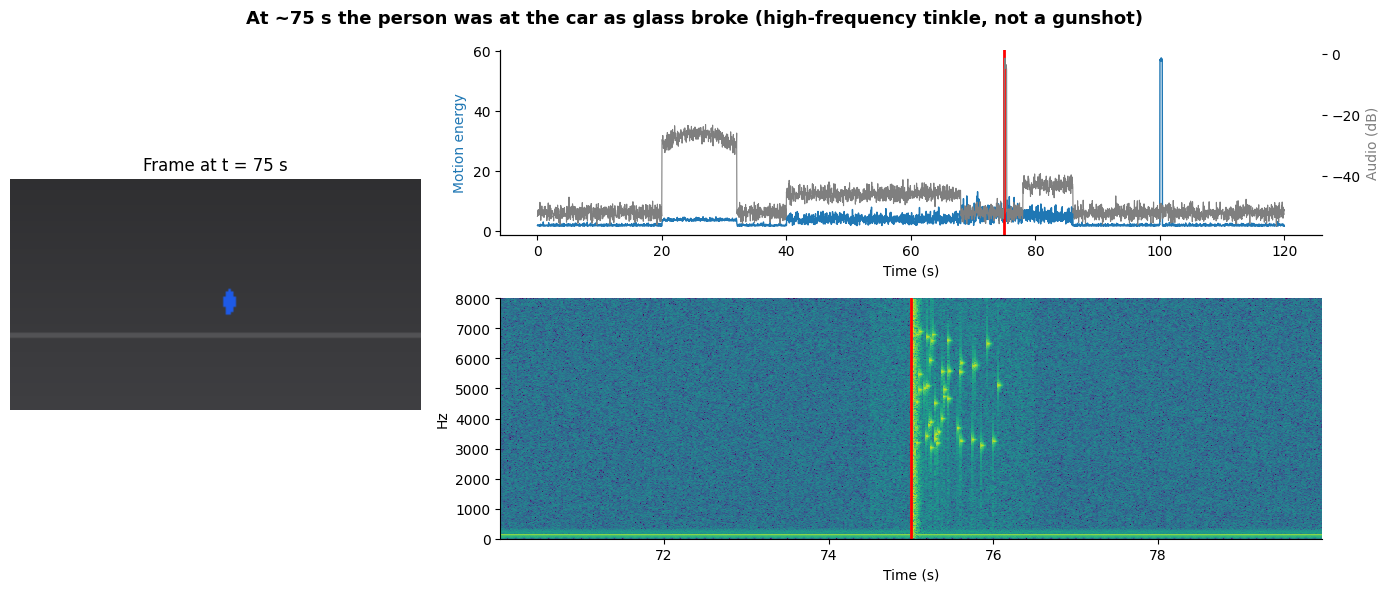

In [11]:
t_sel = 75.0
fig = plt.figure(figsize=(14, 6))
gs = fig.add_gridspec(2, 2, width_ratios=[1, 2], height_ratios=[1, 1.3])

# 1. frame at 75 s (left, spanning both rows)
ax_v = fig.add_subplot(gs[:, 0])
ax_v.imshow(render_frame(cctv.iloc[int(t_sel * FPS)])); ax_v.axis("off")
ax_v.set_title(f"Frame at t = {t_sel:.0f} s")

# 2. motion + audio timeline (top right)
ax_t = fig.add_subplot(gs[0, 1])
t = np.arange(len(cctv)) / FPS
ax_t.plot(t, cctv.motion_energy, color="tab:blue", lw=1)
ax_t.set_ylabel("Motion energy", color="tab:blue")
ax_a = ax_t.twinx()
ax_a.plot(t, cctv.audio_level_db, color="tab:gray", lw=0.8)
ax_a.set_ylabel("Audio (dB)", color="tab:gray")
ax_t.axvline(t_sel, color="red", lw=2)
ax_t.set_xlabel("Time (s)")

# 3. spectrogram 70-80 s (bottom right)
ax_s = fig.add_subplot(gs[1, 1])
f, ts, S = signal.spectrogram(x_audio, fs=FS, nperseg=512, noverlap=384)
ax_s.pcolormesh(ts + 70, f, 10 * np.log10(S + 1e-12), shading="auto")
ax_s.set_ylim(0, 8000); ax_s.axvline(t_sel, color="red", lw=2)
ax_s.set_xlabel("Time (s)"); ax_s.set_ylabel("Hz")

# 4. conclusion-style title
fig.suptitle("At ~75 s the person was at the car as glass broke (high-frequency tinkle, not a gunshot)",
             fontsize=13, weight="bold")
plt.tight_layout(); plt.show()

**Reflection:** Slide 61 warns that combining modalities can cause **information overload** and depends on correct
**synchronization**. What would go wrong in your briefing if the audio track were offset by +2 s from the video?
Which panel would make the mistake visible?

_Your answer:_

If the audio were offset by +2 s, the sound would appear to happen 2 s after the motion it belongs to, or before it. The briefing could then link the glass break to the wrong action, such as the person running or the lighting change. The shared red marker would expose it. The timeline panel would show the audio spike and the motion spike not lining up, and the spectrogram’s tinkle would not match the video frame at the marker.

## Task 6 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence briefing note to the Head of Security covering the whole notebook.
It should:
- State what happened in Lot B in one sentence, with timestamps.
- Justify the **one** visualization you'd put first (timeline, keyframes, spectrogram or the synchronized view),
  using at least one lecture idea (e.g. structure → pattern → change → event → meaning, content-based keyframes,
  time × frequency × magnitude).
- Recommend a storage policy from Task 1 and name the one piece of evidence it must *not* sacrifice.

_Your final briefing here:_

At about 75 s in Lot B, a loud impact was recorded, and its spectrogram matches a glass break, not a gunshot (about 66% of its energy is above 3 kHz, versus about 22% for a gunshot). The timeline also shows [fill in: person standing from X–Y s, running from Z s, lighting jump at W s]. I would put the synchronized view first: it follows the structure → pattern → change → event → meaning flow, and it backs each claim with video and audio at the same timestamp. For storage, uncompressed 1080p/30 fps would be about 5,866 TB/day for 400 cameras, so I recommend 360p/10 fps (about 217 TB/day) with compression. Keep full-resolution, full-frame-rate footage around triggered events (audio spikes, motion), because the fine spatial detail and fast motion that identify people and objects can’t be recovered later.